In [1]:
%pip install pandas numpy scikit-learn matplotlib seaborn torch

   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/126.7 MB 2.0 MB/s eta 0:01:03
   ---------------------------------------- 0.8/126.7 MB 1.7 MB/s eta 0:01:13
   ---------------------------------------- 1.0/126.7 MB 1.5 MB/s eta 0:01:25
   ---------------------------------------- 1.3/126.7 MB 1.4 MB/s eta 0:01:30
   ---------------------------------------- 1.6/126.7 MB 1.4 MB/s eta 0:01:33
    --------------------------------------- 1.8/126.7 MB 1.3 MB/s eta 0:01:40
    --------------------------------------- 1.8/126.7 MB 1.3 MB/s eta 0:01:40
    --------------------------------------- 2.1/126.7 MB 1.2 MB/s eta 0:01:42
    --------------------------------------- 2.4/126.7 MB 1.2 MB/s eta 0:01:45
    --------------------------------------- 2.6/126.7 MB 1.2 MB/s eta 0:01:47
    --------------------------------------- 2.9/126.7 MB 1.1 MB/s eta 0:01:49


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

# Convert labels into numbers
df["label"] = df["label"].map({"ham": 0, "spam": 1})

X = df["message"]
y = df["label"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Data preparation completed!")

Training samples: 4457
Testing samples: 1115
Data preparation completed!


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=3000,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train).toarray()
X_test_tfidf = vectorizer.transform(X_test).toarray()

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)
print("TF-IDF vectorization completed!")

Training shape: (4457, 3000)
Testing shape: (1115, 3000)
TF-IDF vectorization completed!


In [5]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(X_train_tfidf, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test_tfidf, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    drop_last=True
)

print("PyTorch tensors created successfully!")
print("Training batches:", len(train_loader))

PyTorch tensors created successfully!
Training batches: 69


In [6]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train_tensor,
    y_train_tensor,
    test_size=0.2,
    random_state=42,
    stratify=y_train_tensor.numpy()
)

train_dataset = TensorDataset(X_train_part, y_train_part)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, drop_last=True
)

val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 3565
Validation samples: 892


In [7]:
import torch.nn as nn

class SpamClassifier(nn.Module):
    def __init__(self, input_size):
        super(SpamClassifier, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

model = SpamClassifier(X_train_tensor.shape[1])

print(model)

SpamClassifier(
  (network): Sequential(
    (0): Linear(in_features=3000, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [8]:
import torch.optim as optim

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer configured!")

Loss function and optimizer configured!


In [9]:
epochs = 30
patience = 3

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
counter = 0

for epoch in range(epochs):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predictions = (torch.sigmoid(outputs) >= 0.5).float()
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total

    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            predictions = (torch.sigmoid(outputs) >= 0.5).float()
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= len(val_loader)
    val_accuracy = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        torch.save(model.state_dict(), "best_spam_model.pth")
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

model.load_state_dict(torch.load("best_spam_model.pth"))
print("Training completed!")

Epoch 1/30 | Train Loss: 0.3037 | Val Loss: 0.3241 | Val Accuracy: 0.9372
Epoch 2/30 | Train Loss: 0.1042 | Val Loss: 0.1146 | Val Accuracy: 0.9832
Epoch 3/30 | Train Loss: 0.0489 | Val Loss: 0.0807 | Val Accuracy: 0.9832
Epoch 4/30 | Train Loss: 0.0290 | Val Loss: 0.0710 | Val Accuracy: 0.9832
Epoch 5/30 | Train Loss: 0.0195 | Val Loss: 0.0701 | Val Accuracy: 0.9832
Epoch 6/30 | Train Loss: 0.0143 | Val Loss: 0.0611 | Val Accuracy: 0.9832
Epoch 7/30 | Train Loss: 0.0106 | Val Loss: 0.0609 | Val Accuracy: 0.9809
Epoch 8/30 | Train Loss: 0.0089 | Val Loss: 0.0623 | Val Accuracy: 0.9843
Epoch 9/30 | Train Loss: 0.0077 | Val Loss: 0.0633 | Val Accuracy: 0.9832
Epoch 10/30 | Train Loss: 0.0065 | Val Loss: 0.0618 | Val Accuracy: 0.9832
Early stopping triggered!
Training completed!


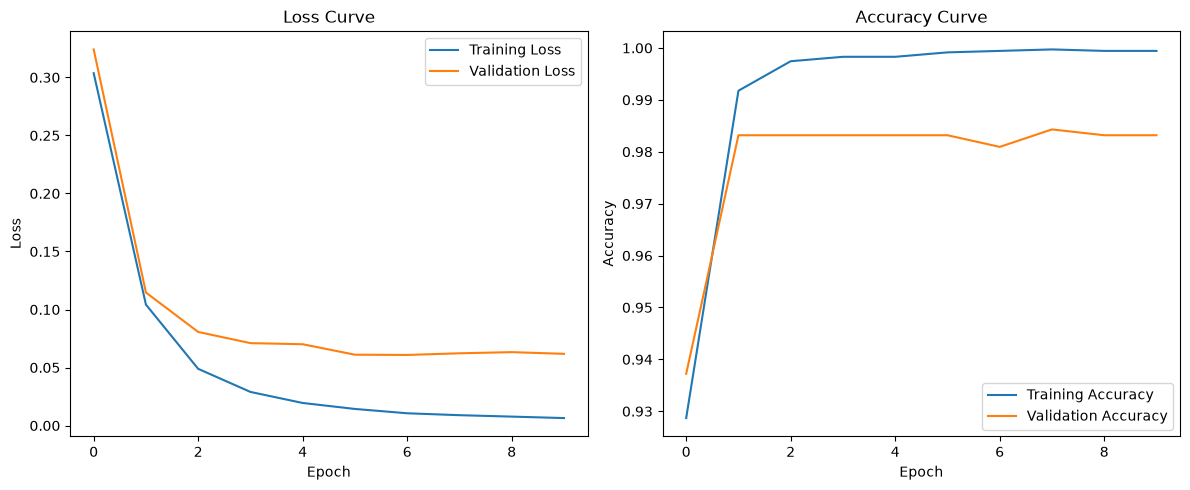

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    probabilities = torch.sigmoid(test_outputs).numpy().flatten()
    predictions = (probabilities >= 0.5).astype(int)

print("Test Accuracy:", accuracy_score(y_test, predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Ham", "Spam"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

Test Accuracy: 0.9820627802690582

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.92      0.95      0.93       149

    accuracy                           0.98      1115
   macro avg       0.96      0.97      0.96      1115
weighted avg       0.98      0.98      0.98      1115


Confusion Matrix:
[[954  12]
 [  8 141]]


In [12]:
def predict_spam(message):
    model.eval()

    message_vector = vectorizer.transform([message]).toarray()
    message_tensor = torch.tensor(message_vector, dtype=torch.float32)

    with torch.no_grad():
        output = model(message_tensor)
        spam_probability = torch.sigmoid(output).item()

    ham_probability = 1 - spam_probability

    prediction = "Spam" if spam_probability >= 0.5 else "Ham"

    print("Message:", message)
    print("Prediction:", prediction)
    print(f"Ham Confidence: {ham_probability * 100:.2f}%")
    print(f"Spam Confidence: {spam_probability * 100:.2f}%")

predict_spam("Congratulations! You have won a free prize. Claim now!")
predict_spam("Hi, are you coming to college tomorrow?")

Message: Congratulations! You have won a free prize. Claim now!
Prediction: Spam
Ham Confidence: 2.32%
Spam Confidence: 97.68%
Message: Hi, are you coming to college tomorrow?
Prediction: Ham
Ham Confidence: 99.72%
Spam Confidence: 0.28%


In [13]:
import joblib

torch.save(model.state_dict(), "best_spam_model.pth")
joblib.dump(vectorizer, "spam_vectorizer.pkl")

print("Model saved successfully!")
print("Vectorizer saved successfully!")

Model saved successfully!
Vectorizer saved successfully!
